# Tarea 2
## Ecuaciones Maestras y Ecuaciones Diferenciales Estocásticas
### Emil Winkler Partida A01352501

### Problema 1
El proceso de Poisson es un proceso en el cual suceden eventos de forma estocástica, pero con un ritmo constante $\lambda$. Un ejemplo de esto es el número de fotones medidos por un detector en un determinado tiempo, o el número de decaimientos de una muestra radiactiva. También sirve para modelar sistemas logísticos como el número de llamadas que entran a un "call center". 

Tamaño de la discretizacion = 100000


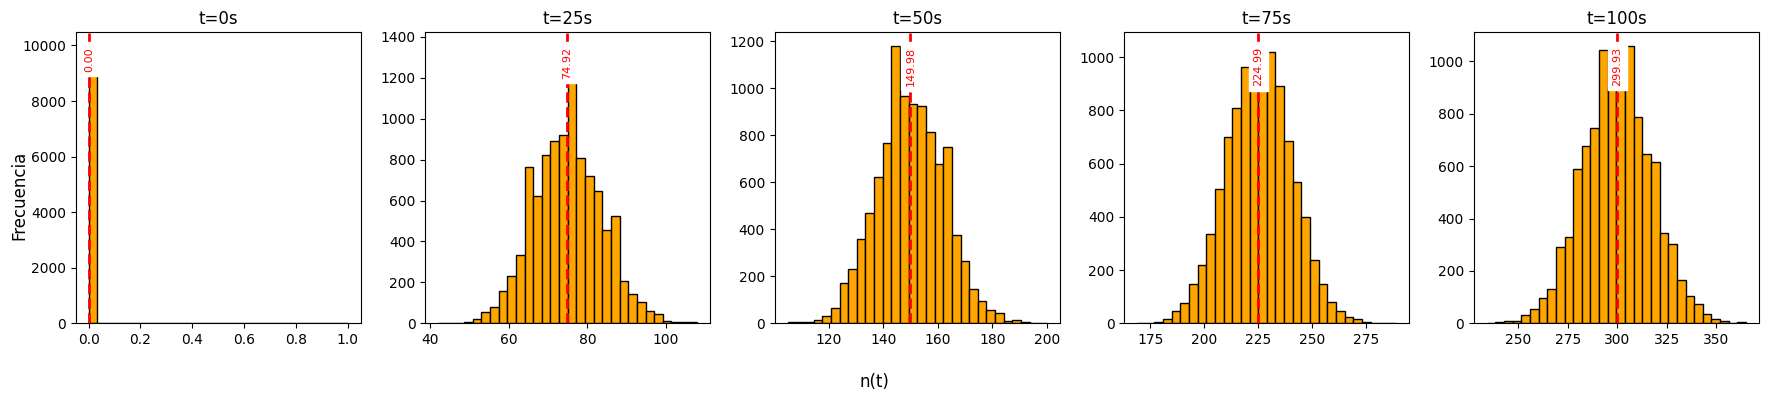

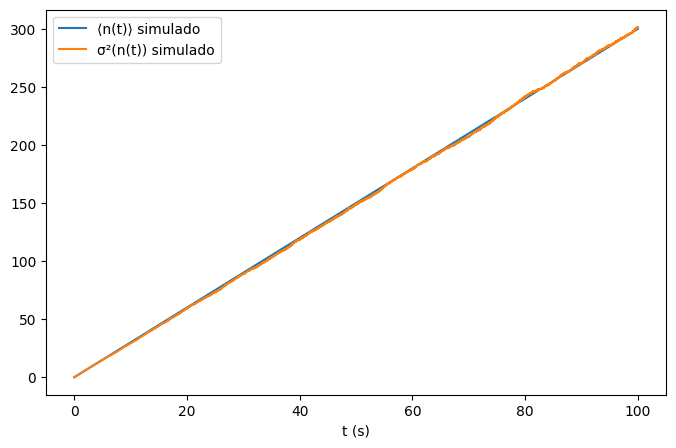

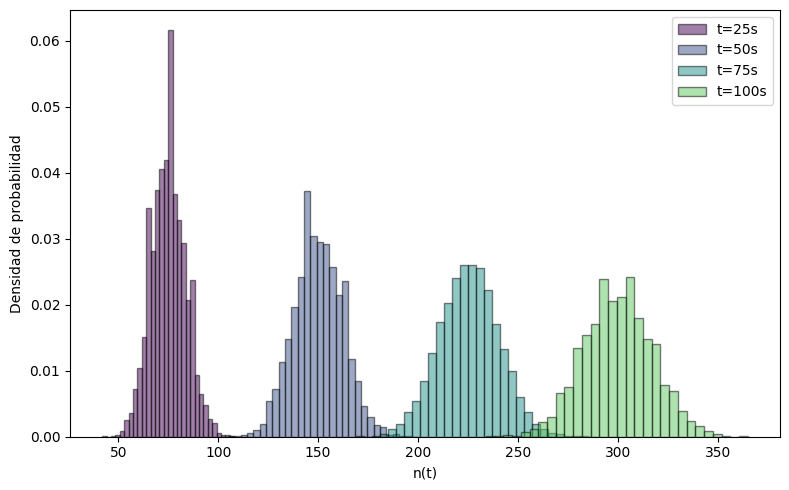

In [8]:
import numpy as np
import matplotlib.pyplot as plt

num_sims = 10000

# Parametros de cada simulacion
lamda = 3 # eventos/s
t_sim = 100 # seg
dt = 0.001
N = int(t_sim/dt)
t = np.zeros(N) # Ejeplo de visualizacion. Aunque despues se describe de forma diferente.

r = np.size(t)
print(f"Tamaño de la discretizacion = {r}")

# Probabilidad para mi dt
p = lamda*dt
q = 1 - p 

# Creamos operador de random para numpy
rng = np.random.default_rng()

#Generacion de numeros aleatorios por simulacion
rand = rng.random((num_sims, N))


# Definir si ocuriio un evento o no (Si rand > p significa que esta en el apartado de 1 - p)
eventos = rng.random((num_sims, N)) < p          # bool, 1 byte/elemento (~1 GB)

# Contamos eventos en base a las probabilidades para cada dt de las simulaciones
'''Conteo acumulado por simulacion (fila), va añadiendo de 1 por 1 los valores convertidos 
por el condicional de eventos'''
n_t = np.cumsum(eventos, axis=1, dtype=np.int32)  # int32 alcanza de sobra (~4 GB)

# Parametros de grafica
t_graf = [0,25, 50, 75, 100]

# Discretizamos y creamos indices para cada uno de los valores de tiempo
''' Usamos N-1 porque nuestro arreglo va de 0 a t_sim - 1 ya que genere N valores a partir del 0'''
indices = [int(t/dt) if t < t_sim else N-1 for t in t_graf]

# Gráficamos los histogramas
fig, axs = plt.subplots(1, len(t_graf), figsize=(18,4))
for ax, t, idx in zip(axs, t_graf, indices):
    ax.hist(n_t[:, idx], bins=30, color="orange", edgecolor="black")
    ax.set_title(f"t={t}s")

    media_emp = np.mean(n_t[:, idx])
    ax.axvline(media_emp, color="red", linestyle='--', linewidth=2)
    ax.text(media_emp, ax.get_ylim()[1]*0.95, f"{media_emp:.2f}",
            color="red", ha="center", va="top", rotation=90,
            backgroundcolor="white", fontsize=8)

fig.supxlabel("n(t)")
fig.supylabel("Frecuencia")
plt.tight_layout()
plt.show()

# Promedio y varianza 
prom_n = np.mean(n_t, axis = 0)
var_n = np.var(n_t, axis=0)


# Promedio y varianza 
prom_n = np.mean(n_t, axis=0)
var_n = np.var(n_t, axis=0)

t_arreglo = np.arange(N) * dt
teorico = lamda * t_arreglo   # E[n(t)] = Var[n(t)] = λt

plt.figure(figsize=(8,5))
plt.plot(t_arreglo, prom_n, label="⟨n(t)⟩ simulado", color="tab:blue")
plt.plot(t_arreglo, var_n, label="σ²(n(t)) simulado", color="tab:orange")
# plt.plot(t_arreglo, teorico, '--', color="black", label="λt (teórico)")
plt.legend()
plt.xlabel("t (s)")
plt.show()

# Gráfica superpuesta de los histogramas en distintos tiempos
colores = plt.cm.viridis(np.linspace(0, 1, len(t_graf)))

# Parámetros de la gráfica
t_sup = [25,50,75,100]
indices_sup = [int(t/dt) if t < t_sim else N-1 for t in t_sup]

#bin_edges = np.linspace(0, n_t.max(), 40)

plt.figure(figsize=(8,5))
for t, idx, color in zip(t_sup, indices_sup, colores):
    plt.hist(n_t[:, idx], bins=30, alpha=0.5, color=color,
              label=f"t={t}s", density=True, edgecolor='black')
plt.xlabel("n(t)")
plt.ylabel("Densidad de probabilidad")
plt.legend()
plt.tight_layout()
plt.show()

### Problema 2

Una idea similar se puede utilizar para modelar la propagación de epidemias. Supongamos que tenemos una población, cuyos individuos pueden clasificarse como Susceptible, Infectada o Recuperada (S, I, R). Existen dos posibles transiciones, S -> I y I -> R. Sin embargo, en este caso el ritmo con que ocurre la primera transición depende de el número de infectados multiplicado por un coeficiente $\beta$, mientras que el ritmo con que ocurre la segunda transición está dado por $\gamma$
.   

Tiempo total: 13.0s


C:\Users\Emil\AppData\Roaming\Python\Python313\site-packages\IPython\core\pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


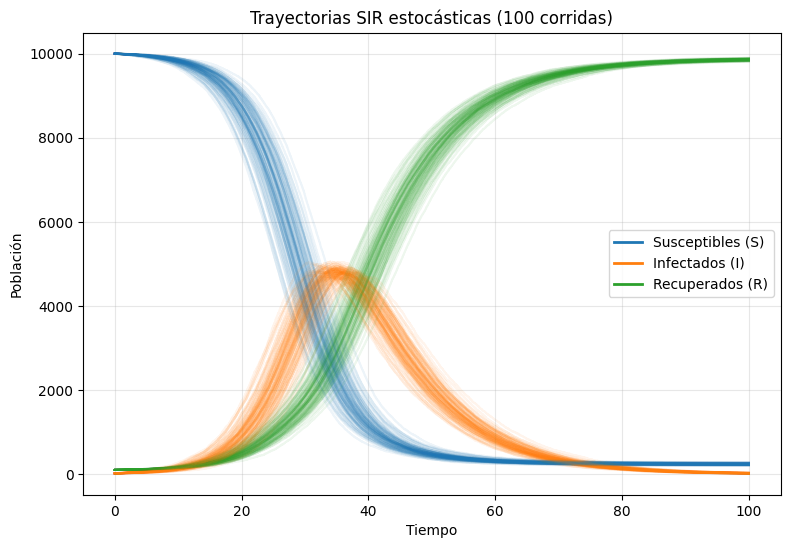

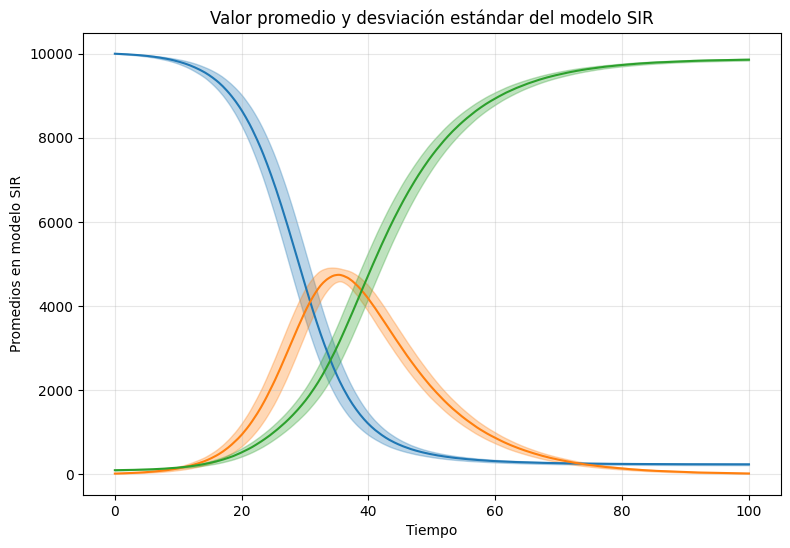

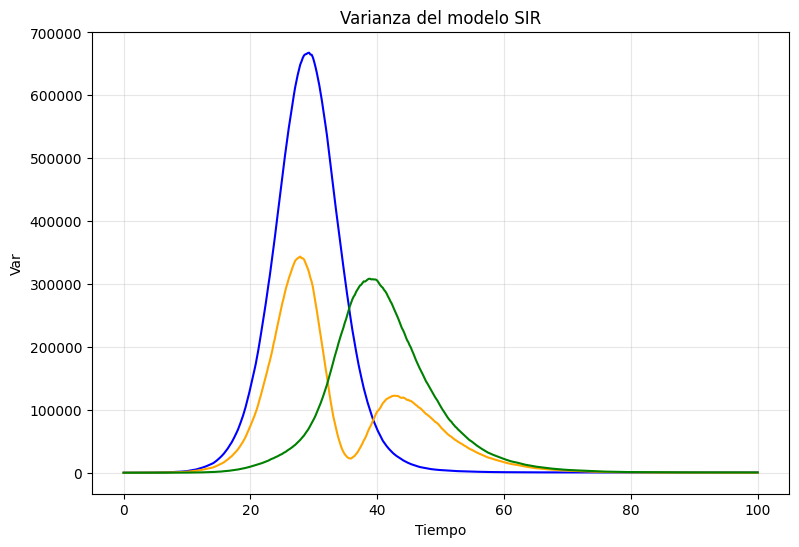

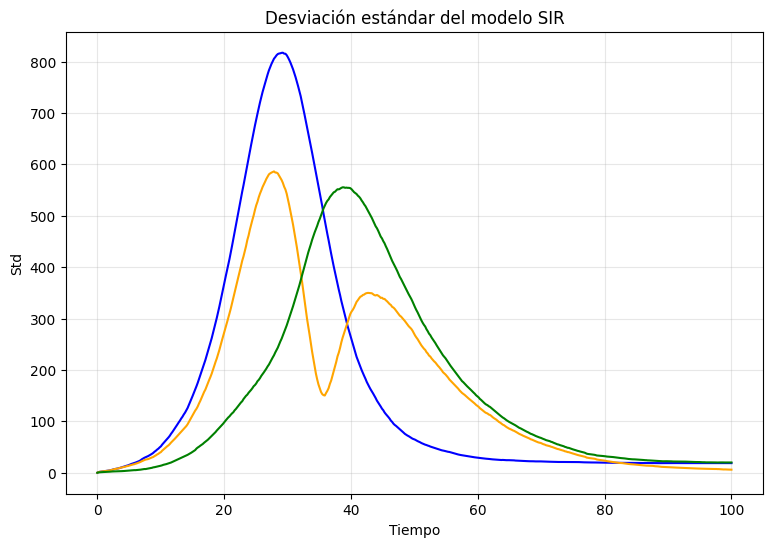

In [ ]:
import time
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D


def simular_trayectoria(beta, gamma, s0, i0, r0, t_sim, seed=None):
    rng = np.random.default_rng(seed)  # Cada corrida necesita su propia semilla para no tener misma realizacion
    
    # Definimos condiciones iniciales
    t = 0
    s, i, r = s0, i0, r0
    N = s0 + i0 + r0
    dt = 0.001
    
    
    # Creamos listas con condiciones iniciales
    tiempos = [t]
    S, I, R = [s], [i], [r]
    
    # Alforitmo de Gillespie 
    while t < t_sim and i > 0:
        W_inf = (beta/N) * s * i *dt
        W_rec = gamma * i *dt
        W_tot = W_inf + W_rec
        
        rand1 = rng.random()
        # dt = -np.log(rand1) / W_tot
        t += dt
        
        rand2 = rng.random()
        if rand1 < W_inf:
            s -= 1
            i += 1
        elif rand2 <W_rec:
            i -= 1
            r += 1
            
        tiempos.append(t)
        S.append(s)
        I.append(i)
        R.append(r)
    
    return np.array(tiempos), np.array(S), np.array(I), np.array(R)



M = 100
beta, gamma = 0.3, 0.1
s0, i0, r0 = 10000, 20, 100
t_sim = 100

t0 = time.time()
resultados = [simular_trayectoria(beta, gamma, s0, i0, r0, t_sim, seed) for seed in range(M)]
print(f"Tiempo total: {time.time()-t0:.1f}s")

### Graficacion 
# fig, axes = plt.subplots(3,1, figsize = (9,10), sharex=True)

# for tiempos, S, I, R in resultados[:100]:
#     axes[0].step(tiempos, S, where='post', color='tab:blue', alpha=0.05)
#     axes[1].step(tiempos, I, where='post', color='tab:orange', alpha=0.05)
#     axes[2].step(tiempos, R, where='post', color='tab:green', alpha=0.05)

# axes[0].set_ylabel('Susceptibles (S)')
# axes[1].set_ylabel('Infectados (I)')
# axes[2].set_ylabel('Recuperados (R)')
# axes[2].set_xlabel('Tiempo')

# for ax in axes:
#     ax.grid(alpha=0.3)

# fig.suptitle(f'Trayectorias SIR estocásticas ({100} corridas)')
# plt.tight_layout()
# plt.show()

# Grafica de SIR general
plt.figure(figsize=(9, 6))

for idx, (tiempos, S, I, R) in enumerate(resultados[:100]):
    # label solo en la primera iteración, para no repetir 100 entradas en la leyenda
    plt.step(tiempos, S, where='post', color='tab:blue', alpha=0.08)
    plt.step(tiempos, I, where='post', color='tab:orange', alpha=0.08)
    plt.step(tiempos, R, where='post', color='tab:green', alpha=0.08)

legend_elements = [
    Line2D([0], [0], color='tab:blue', lw=2, label='Susceptibles (S)'),
    Line2D([0], [0], color='tab:orange', lw=2, label='Infectados (I)'),
    Line2D([0], [0], color='tab:green', lw=2, label='Recuperados (R)'),
]

plt.xlabel('Tiempo')
plt.ylabel('Población')
plt.title(f'Trayectorias SIR estocásticas ({100} corridas)')
plt.legend(handles = legend_elements)
plt.grid(alpha=0.3)
plt.show()

# Definir la media y varianza
'''Para realizar un análisis completo del modelo Estocastico, es importante analizar todas las 
realizaciones de simulación y por lo tanto todas las corridas de mi simulación. No obstante, en 
Gillespie cada paso temporal es diferente para cada trayectoria y para cada valor, por lo que no 
es posible comparar directamente. Por lo tanto tenemos que interpolar los resultados a un timeline
conjunto que sea de utilidad '''

t_interp = np.linspace(0, t_sim, 500)

S_interp = np.array([np.interp(t_interp, tiempos, S, right=S[-1]) for tiempos, S, I, R in resultados])
I_interp = np.array([np.interp(t_interp, tiempos, I, right=I[-1]) for tiempos, S, I, R in resultados])
R_interp = np.array([np.interp(t_interp, tiempos, R, right=R[-1]) for tiempos, S, I, R in resultados])

S_mean, S_var, S_std = S_interp.mean(axis = 0), S_interp.var(axis = 0), S_interp.std(axis=0) # Axis = 0 Sirve para que calcule el promedio por columna
I_mean, I_var, I_std= I_interp.mean(axis = 0), I_interp.var(axis = 0 ), I_interp.std(axis=0) 
R_mean, R_var, R_std = R_interp.mean(axis = 0), R_interp.var(axis = 0), R_interp.std(axis=0) 

plt.figure(figsize = (9,6))

plt.plot(t_interp, S_mean, color='tab:blue')
plt.fill_between(t_interp, S_mean - S_std, S_mean + S_std, alpha=0.3, color='tab:blue')
plt.plot(t_interp, I_mean, color='tab:orange')
plt.fill_between(t_interp, I_mean - I_std, I_mean + I_std, alpha=0.3, color='tab:orange')
plt.plot(t_interp, R_mean, color='tab:green')
plt.fill_between(t_interp, R_mean - R_std, R_mean + R_std, alpha=0.3, color='tab:green') 
plt.ylabel("Promedios en modelo SIR")
plt.xlabel('Tiempo')
plt.title(f"Valor promedio y desviación estándar del modelo SIR")
plt.grid(alpha= 0.3)
plt.show()

plt.figure(figsize = (9,6))

plt.plot(t_interp, S_var, label = 'Var Susceptibles', color="blue")
plt.plot(t_interp, I_var, label = 'Var Infectados', color="orange")
plt.plot(t_interp, R_var, label = 'Var Recuperado', color="green")
plt.xlabel("Tiempo")
plt.ylabel("Var")
plt.title(f"Varianza del modelo SIR")
plt.grid(alpha= 0.3)
plt.show()

plt.figure(figsize = (9,6))

plt.plot(t_interp, S_std, label = 'Std Susceptibles', color="blue")
plt.plot(t_interp, I_std, label = 'Std Infectados', color="orange")
plt.plot(t_interp, R_std, label = 'Std Recuperado', color="green")
plt.xlabel("Tiempo")
plt.ylabel("Std")
plt.title(f"Desviación estándar del modelo SIR")
plt.grid(alpha= 0.3)
plt.show()

### Pruebas de mejor graficacion de modelo SIR

Tiempo total: 35.5s


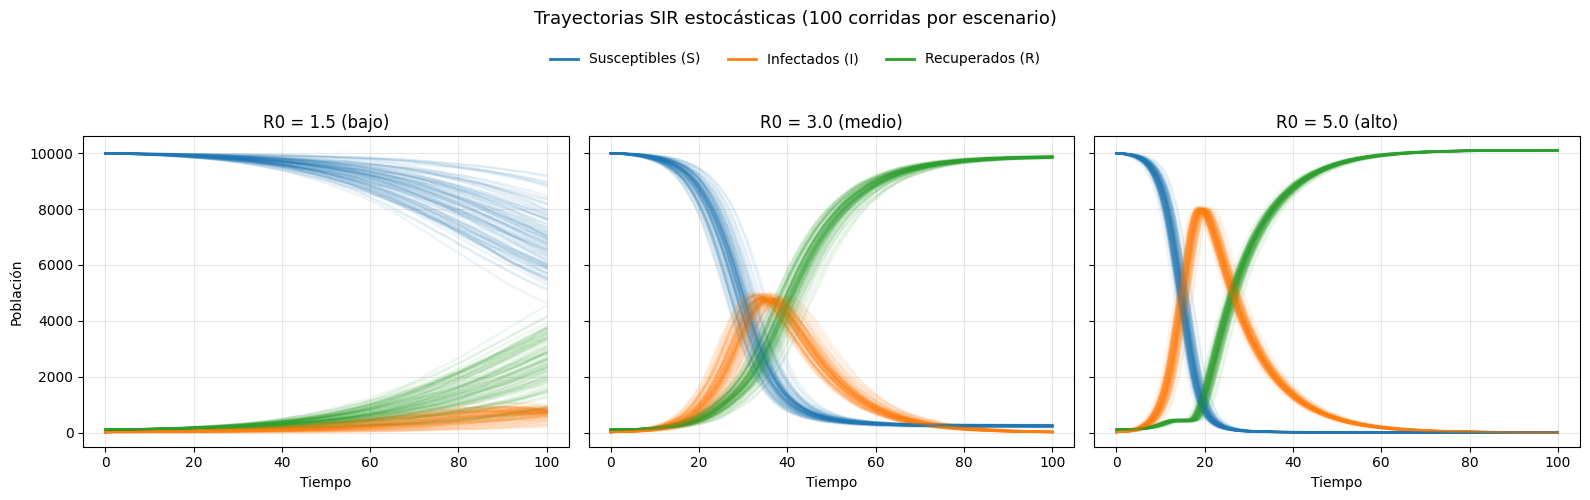

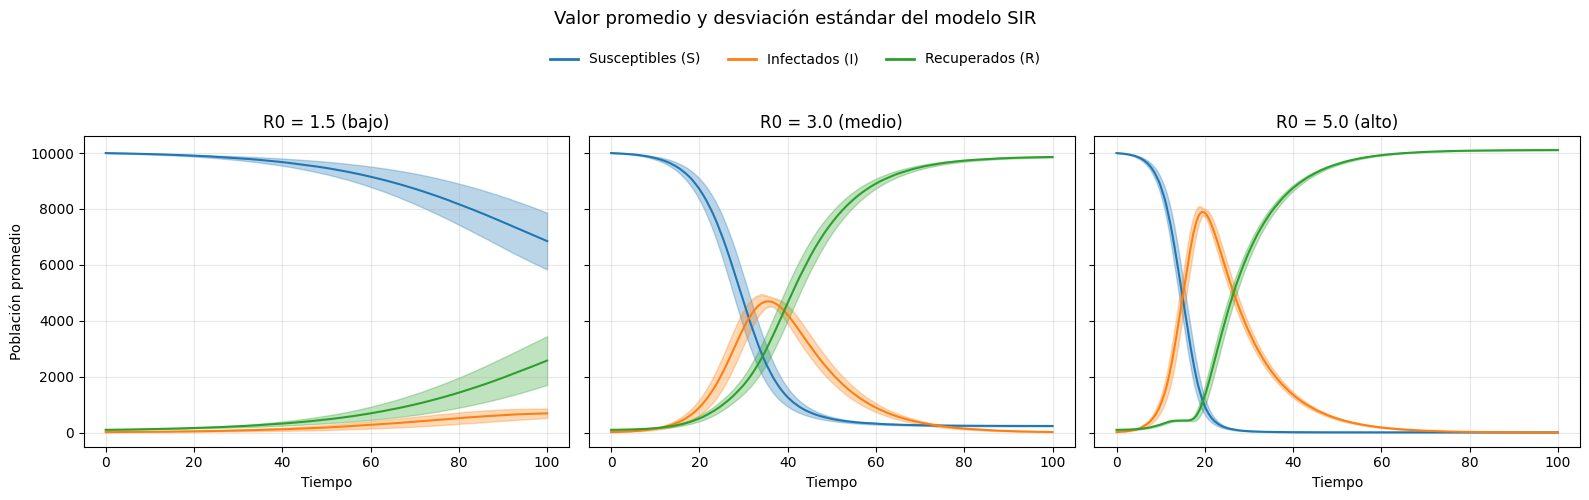

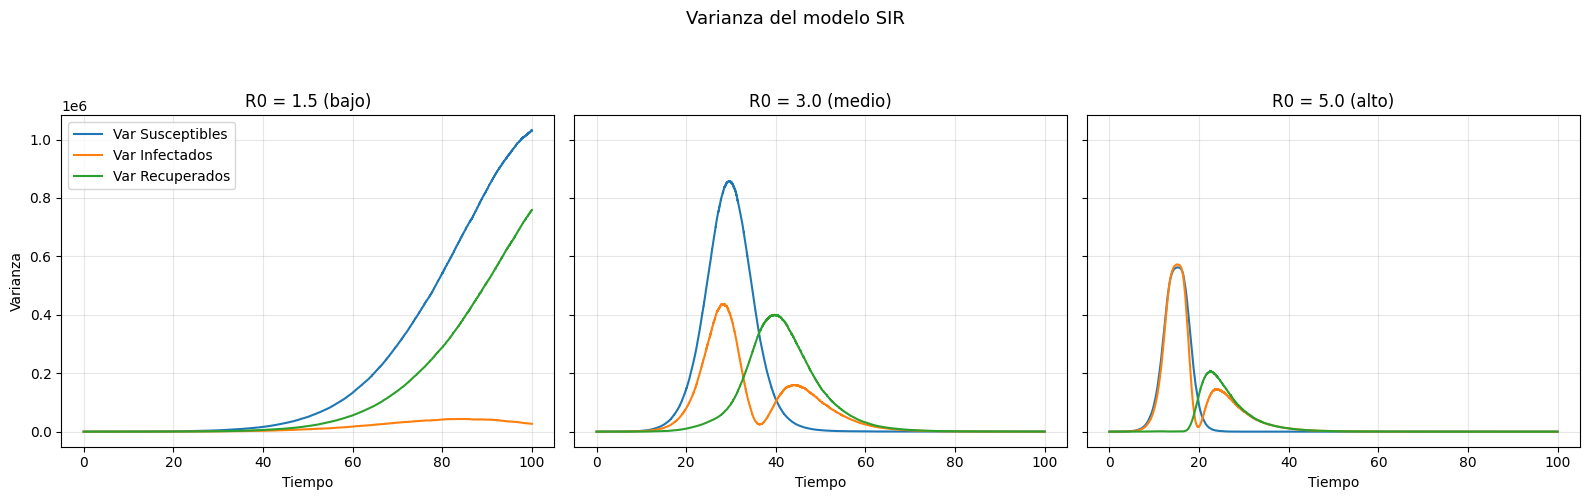

In [ ]:
import time
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D


def simular_trayectoria(beta, gamma, s0, i0, r0, t_sim, seed=None):
    rng = np.random.default_rng(seed)  # Cada corrida necesita su propia semilla para no tener misma realizacion

    # Definimos condiciones iniciales
    t = 0
    s, i, r = s0, i0, r0
    N = s0 + i0 + r0
    dt = 0.001

    # Creamos listas con condiciones iniciales
    tiempos = [t]
    S, I, R = [s], [i], [r]

    # Cadena de Markov a tiempo discreto (dt fijo, sin paso variable)
    while t < t_sim and i > 0:
        W_inf = (beta / N) * s * i * dt
        W_rec = gamma * i * dt

        rand1 = rng.random()
        t += dt

        rand2 = rng.random()
        if rand1 < W_inf:
            s -= 1
            i += 1
        elif rand2 < W_rec:
            i -= 1
            r += 1

        tiempos.append(t)
        S.append(s)
        I.append(i)
        R.append(r)

    return np.array(tiempos), np.array(S), np.array(I), np.array(R)


def _extender_a_longitud(x, n):
    """Si la trayectoria se extingue (I=0) antes de t_sim, el estado ya no
    cambia (S y R quedan fijos), así que basta con repetir el último valor
    hasta completar n pasos — no hace falta interpolar."""
    if len(x) >= n:
        return x[:n]
    return np.concatenate([x, np.full(n - len(x), x[-1])])


def correr_escenario(beta, gamma, s0, i0, r0, t_sim, M, seed_base=0):
    """Corre M realizaciones de la cadena de Markov para un set de
    condiciones iniciales. Como dt es fijo, todas las corridas comparten
    la misma malla temporal; solo se extienden las que se extinguieron
    antes de t_sim para poder apilarlas y sacar estadísticas."""

    resultados = [
        simular_trayectoria(beta, gamma, s0, i0, r0, t_sim, seed_base + k)
        for k in range(M)
    ]

    largos = [len(t_) for t_, S, I, R in resultados]
    n_pasos = max(largos)
    t_comun = resultados[int(np.argmax(largos))][0]

    S_mat = np.array([_extender_a_longitud(S, n_pasos) for t_, S, I, R in resultados])
    I_mat = np.array([_extender_a_longitud(I, n_pasos) for t_, S, I, R in resultados])
    R_mat = np.array([_extender_a_longitud(R, n_pasos) for t_, S, I, R in resultados])

    stats = {
        'S_mean': S_mat.mean(axis=0), 'S_var': S_mat.var(axis=0), 'S_std': S_mat.std(axis=0),
        'I_mean': I_mat.mean(axis=0), 'I_var': I_mat.var(axis=0), 'I_std': I_mat.std(axis=0),
        'R_mean': R_mat.mean(axis=0), 'R_var': R_mat.var(axis=0), 'R_std': R_mat.std(axis=0),
    }
    return resultados, t_comun, stats


# ----------------------------------------------------------------------
# Escenarios con distintas condiciones iniciales
# (aquí varío beta -> distintos R0; cambia estos valores si quieres
#  comparar otra cosa, como i0 o el tamaño de la población)
# ----------------------------------------------------------------------
escenarios = [
    {'nombre': 'R0 = 1.5 (bajo)',  'beta': 0.15, 'gamma': 0.1, 's0': 10000, 'i0': 20, 'r0': 100},
    {'nombre': 'R0 = 3.0 (medio)', 'beta': 0.30, 'gamma': 0.1, 's0': 10000, 'i0': 20, 'r0': 100},
    {'nombre': 'R0 = 5.0 (alto)',  'beta': 0.50, 'gamma': 0.1, 's0': 10000, 'i0': 20, 'r0': 100},
]

M = 100
t_sim = 100

t0 = time.time()
datos_escenarios = []
for k, esc in enumerate(escenarios):
    resultados, t_comun, stats = correr_escenario(
        esc['beta'], esc['gamma'], esc['s0'], esc['i0'], esc['r0'], t_sim, M, seed_base=k * M
    )
    datos_escenarios.append((esc, resultados, t_comun, stats))
print(f"Tiempo total: {time.time() - t0:.1f}s")

legend_elements = [
    Line2D([0], [0], color='tab:blue', lw=2, label='Susceptibles (S)'),
    Line2D([0], [0], color='tab:orange', lw=2, label='Infectados (I)'),
    Line2D([0], [0], color='tab:green', lw=2, label='Recuperados (R)'),
]

# ----------------------------------------------------------------------
# Figura 1: Trayectorias estocásticas — un panel por escenario
# ----------------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharey=True)
for ax, (esc, resultados, t_comun, stats) in zip(axes, datos_escenarios):
    for tiempos, S, I, R in resultados:
        ax.step(tiempos, S, where='post', color='tab:blue', alpha=0.08)
        ax.step(tiempos, I, where='post', color='tab:orange', alpha=0.08)
        ax.step(tiempos, R, where='post', color='tab:green', alpha=0.08)
    ax.set_title(esc['nombre'])
    ax.set_xlabel('Tiempo')
    ax.grid(alpha=0.3)
axes[0].set_ylabel('Población')
fig.suptitle(f'Trayectorias SIR estocásticas ({M} corridas por escenario)', y=0.99, fontsize=13)
fig.legend(handles=legend_elements, loc='upper center', bbox_to_anchor=(0.5, 0.93), ncol=3, frameon=False)
fig.tight_layout(rect=[0, 0, 1, 0.88])
plt.show()

# ----------------------------------------------------------------------
# Figura 2: Promedio ± desviación estándar — un panel por escenario
# ----------------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharey=True)
for ax, (esc, resultados, t_comun, stats) in zip(axes, datos_escenarios):
    ax.plot(t_comun, stats['S_mean'], color='tab:blue')
    ax.fill_between(t_comun, stats['S_mean'] - stats['S_std'], stats['S_mean'] + stats['S_std'],
                     alpha=0.3, color='tab:blue')
    ax.plot(t_comun, stats['I_mean'], color='tab:orange')
    ax.fill_between(t_comun, stats['I_mean'] - stats['I_std'], stats['I_mean'] + stats['I_std'],
                     alpha=0.3, color='tab:orange')
    ax.plot(t_comun, stats['R_mean'], color='tab:green')
    ax.fill_between(t_comun, stats['R_mean'] - stats['R_std'], stats['R_mean'] + stats['R_std'],
                     alpha=0.3, color='tab:green')
    ax.set_title(esc['nombre'])
    ax.set_xlabel('Tiempo')
    ax.grid(alpha=0.3)
axes[0].set_ylabel('Población promedio')
fig.suptitle('Valor promedio y desviación estándar del modelo SIR', y=0.99, fontsize=13)
fig.legend(handles=legend_elements, loc='upper center', bbox_to_anchor=(0.5, 0.93), ncol=3, frameon=False)
fig.tight_layout(rect=[0, 0, 1, 0.88])
plt.show()

# ----------------------------------------------------------------------
# Figura 3: Varianza — un panel por escenario
# ----------------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharey=True)
for ax, (esc, resultados, t_comun, stats) in zip(axes, datos_escenarios):
    ax.plot(t_comun, stats['S_var'], label='Var Susceptibles', color='tab:blue')
    ax.plot(t_comun, stats['I_var'], label='Var Infectados', color='tab:orange')
    ax.plot(t_comun, stats['R_var'], label='Var Recuperados', color='tab:green')
    ax.set_title(esc['nombre'])
    ax.set_xlabel('Tiempo')
    ax.grid(alpha=0.3)
axes[0].set_ylabel('Varianza')
axes[0].legend()
fig.suptitle('Varianza del modelo SIR', y=0.99, fontsize=13)
fig.tight_layout(rect=[0, 0, 1, 0.92])
plt.show()

### Problema 3. 


En clase definimos el proceso de Wiener como:

$$
W(t) = \int_0^t dW
$$

donde $dW$ es una variable aleatoria con distribución Gaussiana,

$$
\langle dW \rangle = 0
$$

y

$$
\langle dW^2 \rangle = dt
$$

Simularemos el proceso de Wiener numéricamente en un intervalo de **100 segundos**. Dividiremos el espacio del tiempo en $N$ intervalos $dt$.




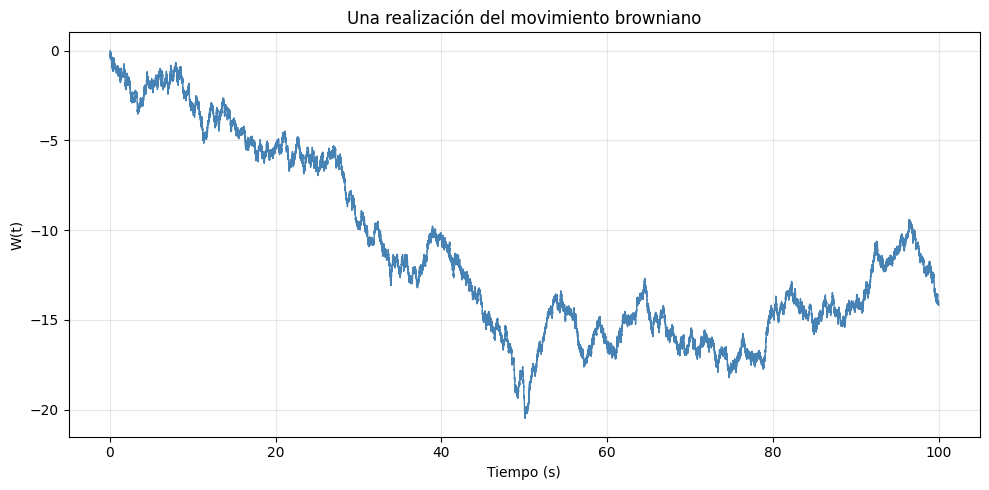

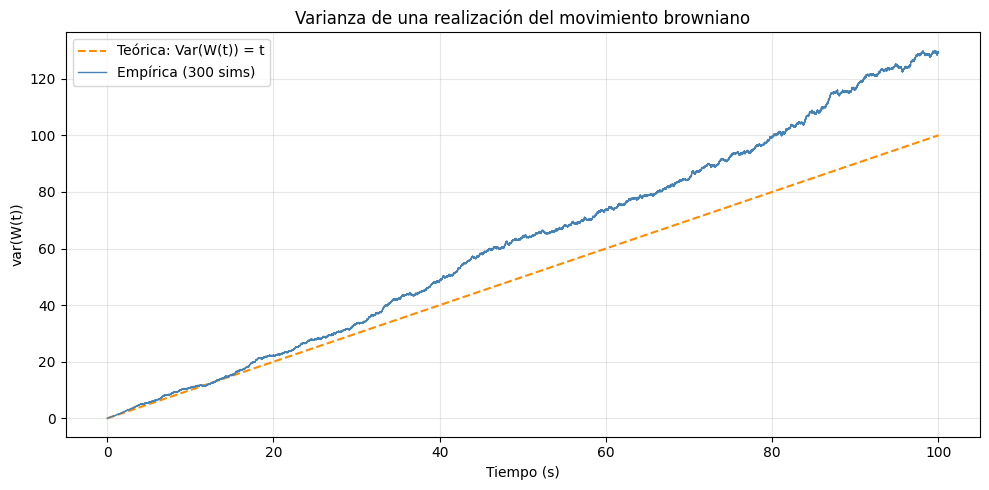

C:\Users\Emil\AppData\Local\Temp\ipykernel_2768\2166316429.py:93: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


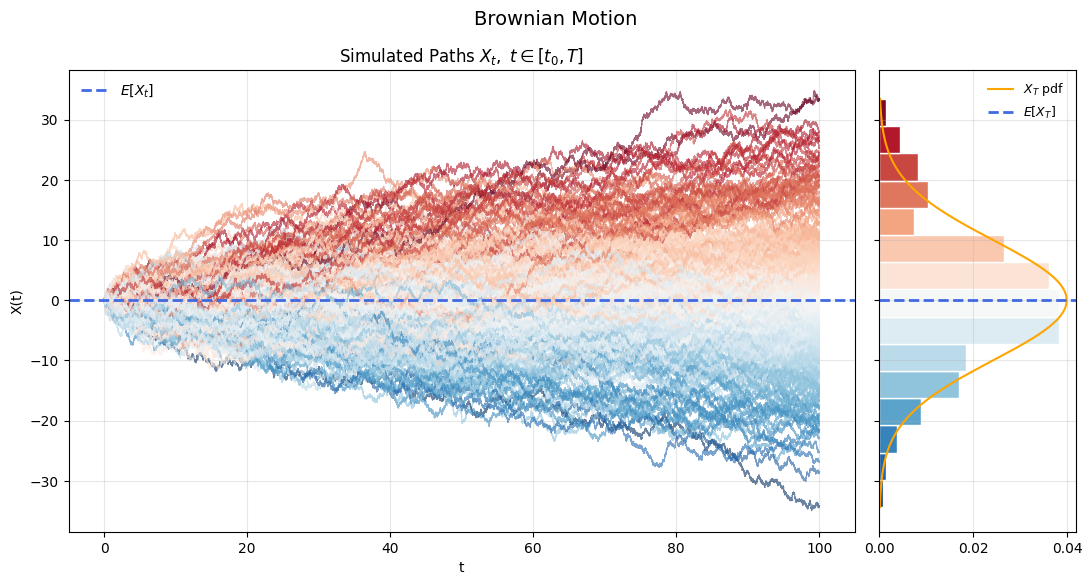

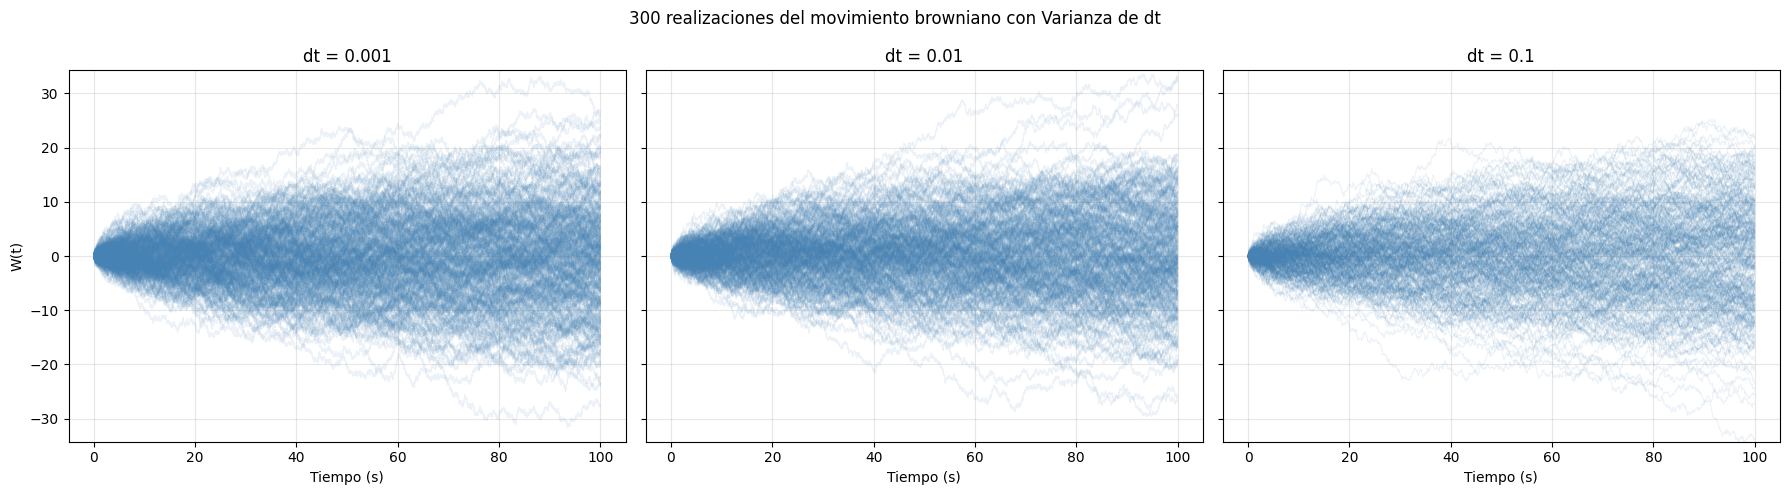

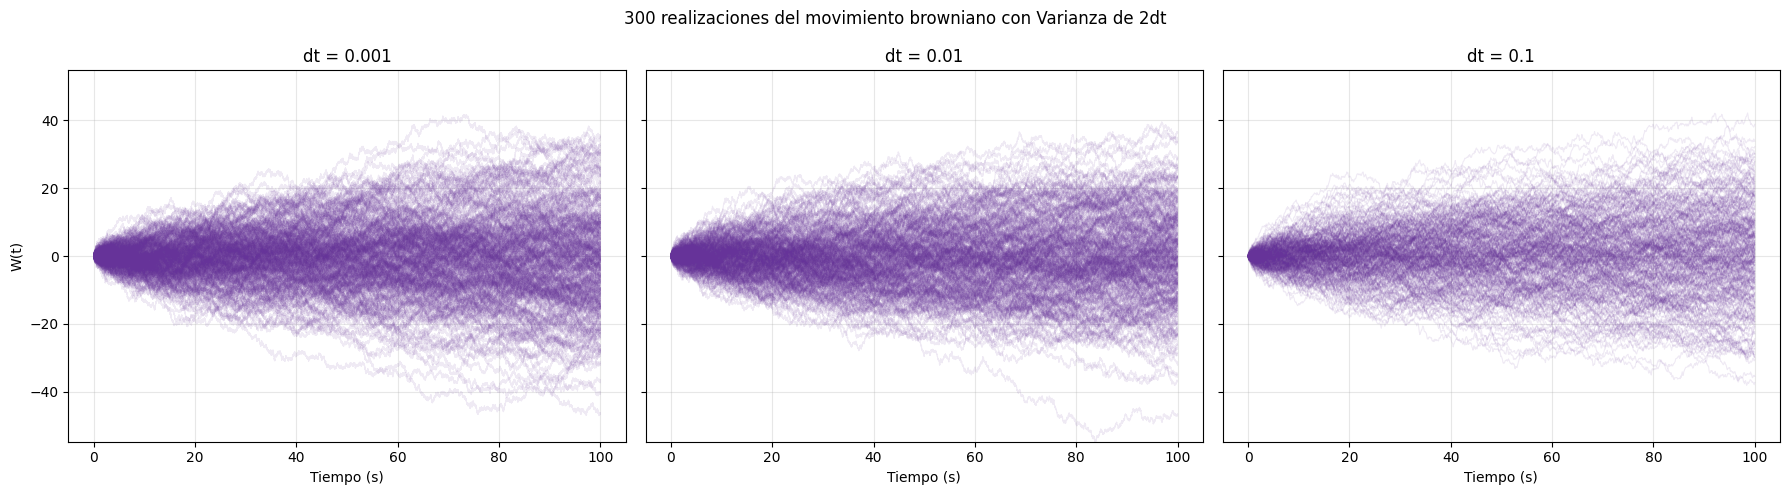

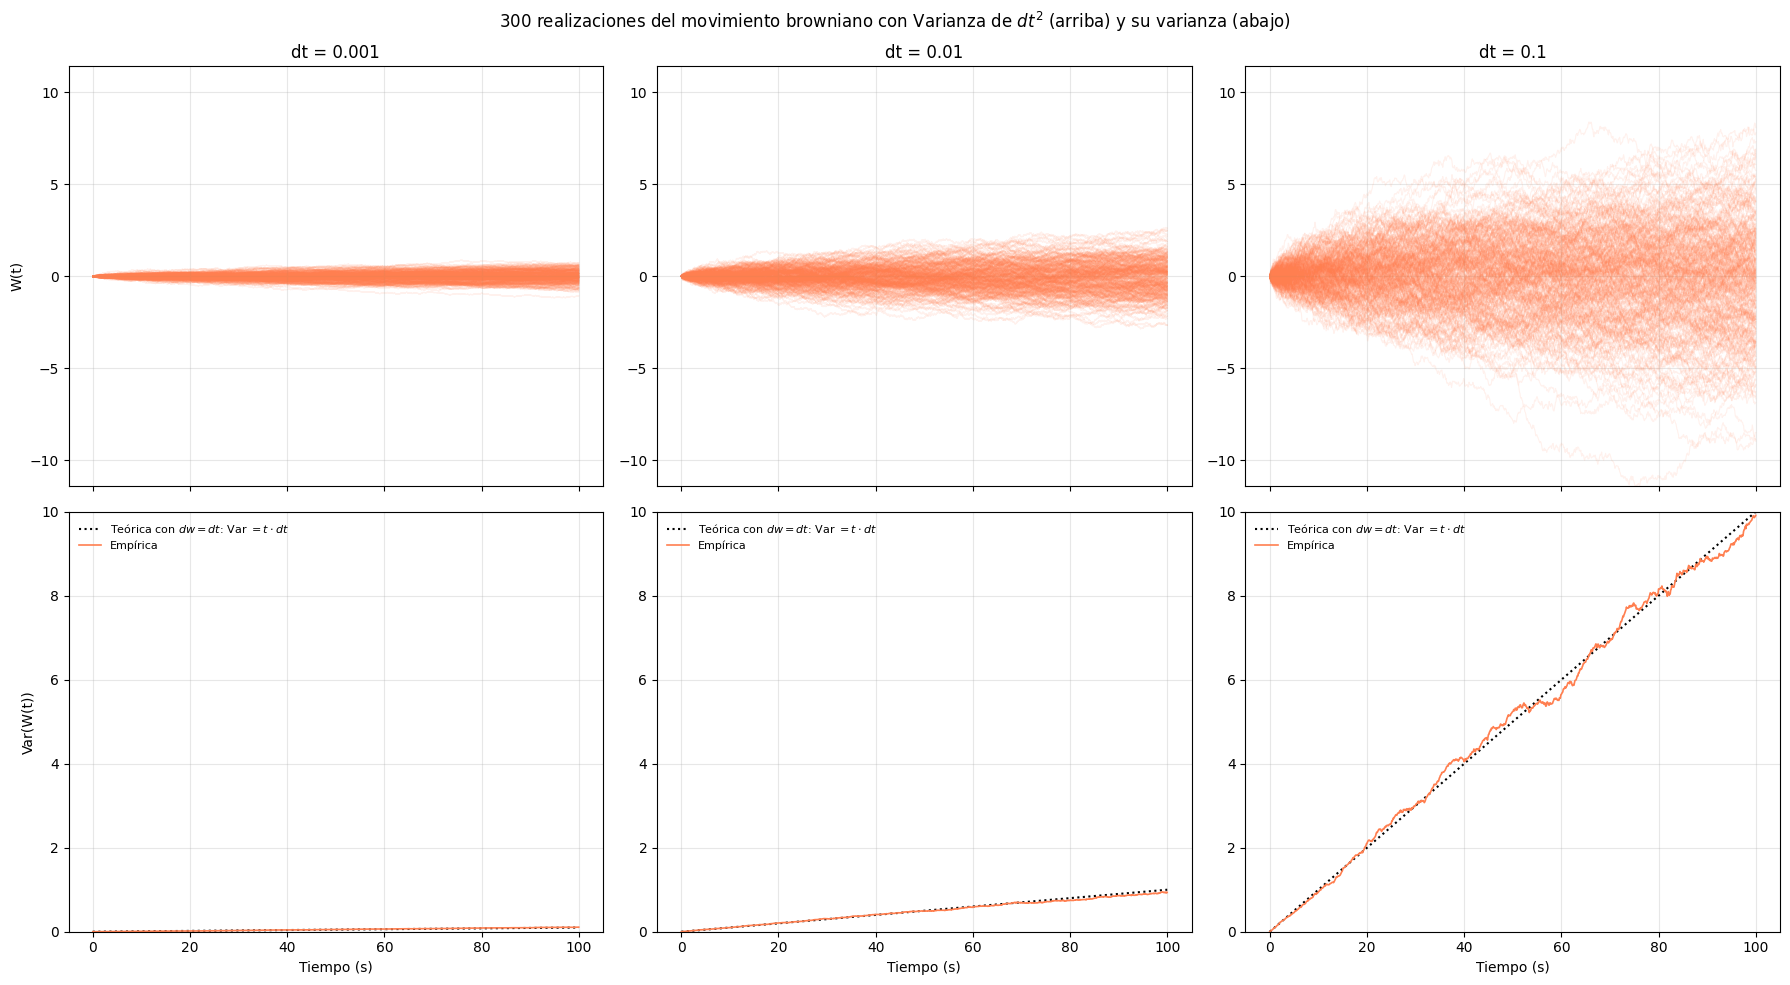

In [27]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from scipy.stats import norm

dt = 0.001
dts = [0.001, 0.01, 0.1]
t_sim=100
num_sims = 300
results = {}

def simulacion_wiener(dt, dw=np.sqrt(dt), t_sim=100, num_sims =300):
    N = int(t_sim/dt)
    # Obligo a que la primera funcion sea 0 con el insert
    t = np.linspace(0, t_sim, N+1)
    rand = np.random.randn(num_sims,N) 
    dW = np.insert(rand * dw, 0, 0, axis=1)
    process = np.cumsum(dW, axis=1)
    # print(f"The shape of dw is {np.shape(dW)} and the shape of process is {np.shape(process)}")
 
    return t, process, dW  

t, process, dW = simulacion_wiener(0.001)
# Gráfica 1: una sola realización (por ejemplo, la primera)
plt.figure(figsize=(10, 5))
plt.plot(t, process[0], color='steelblue', linewidth=1)
plt.xlabel('Tiempo (s)')
plt.ylabel('W(t)')
plt.title('Una realización del movimiento browniano')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 5))
plt.plot(t, t, '--', color='darkorange', label='Teórica: Var(W(t)) = t')
plt.plot(t, process.var(axis=0), color='steelblue', linewidth=1, label='Empírica (300 sims)')
plt.legend()
plt.xlabel('Tiempo (s)')
plt.ylabel('var(W(t))')
plt.title('Varianza de una realización del movimiento browniano')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()



#---- Grafica doble con distribucion de probabilidad -----
final_vals = process[:, -1]

# --- Figura con 2 paneles que comparten eje Y ---
fig = plt.figure(figsize=(13, 6))
gs = GridSpec(1, 2, width_ratios=[4, 1], wspace=0.05)
ax_paths = fig.add_subplot(gs[0])
ax_hist = fig.add_subplot(gs[1], sharey=ax_paths)

# --- Panel izquierdo: trayectorias coloreadas por valor final ---
norm_color = plt.Normalize(final_vals.min(), final_vals.max())
cmap = plt.cm.RdBu_r   

for i in range(num_sims):
    ax_paths.plot(t, process[i], color=cmap(norm_color(final_vals[i])),
                  alpha=0.6, linewidth=0.8)

ax_paths.axhline(0, color='royalblue', linestyle='--', linewidth=2, label=r'$E[X_t]$')
ax_paths.set_xlabel('t')
ax_paths.set_ylabel('X(t)')
ax_paths.set_title(r'Simulated Paths $X_t,\ t \in [t_0, T]$')
ax_paths.legend(loc='upper left', frameon=False)
ax_paths.grid(alpha=0.3)

# --- Panel derecho: histograma horizontal de X_T + pdf teórica ---
counts, bins, patches = ax_hist.hist(final_vals, bins=15, orientation='horizontal',
                                       density=True, edgecolor='white')

# Colorear cada barra según el punto medio de su bin (mismo cmap que las trayectorias)
bin_centers = 0.5 * (bins[:-1] + bins[1:])
for count, patch, center in zip(counts, patches, bin_centers):
    patch.set_facecolor(cmap(norm_color(center)))

# Curva de densidad teórica: X_T ~ N(0, t_sim) para este proceso
mu, sigma = 0, np.sqrt(t_sim)
y_range = np.linspace(final_vals.min(), final_vals.max(), 200)
pdf = norm.pdf(y_range, mu, sigma)
ax_hist.plot(pdf, y_range, color='orange', linewidth=1.5, label=r'$X_T$ pdf')

ax_hist.axhline(0, color='royalblue', linestyle='--', linewidth=2, label=r'$E[X_T]$')
ax_hist.set_xlabel('')
ax_hist.legend(loc='upper right', frameon=False, fontsize=9)
ax_hist.tick_params(labelleft=False)  # oculta las etiquetas del eje Y (compartido)
ax_hist.grid(alpha=0.3)

fig.suptitle('Brownian Motion', fontsize=14)
plt.tight_layout()
plt.show()

## ----- Varianza de dt -----
for dt in dts:
    t, process, dW = simulacion_wiener(dt, dw=np.sqrt(dt) ,num_sims=num_sims)
    results[dt] = (t, process)

# Para comparar de forma justa, usamos el mismo límite en el eje Y en las 3 gráficas
y_max = max(np.abs(results[dt][1]).max() for dt in dts)

fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)

for ax, dt in zip(axes, dts):
    t, process = results[dt]
    for i in range(num_sims):
        ax.plot(t, process[i], color='steelblue', alpha=0.1, linewidth=0.8)
    ax.set_xlabel('Tiempo (s)')
    ax.set_title(f'dt = {dt}')
    ax.set_ylim(-y_max, y_max)
    ax.grid(True, alpha=0.3)

axes[0].set_ylabel('W(t)')
fig.suptitle(r'300 realizaciones del movimiento browniano con Varianza de dt')
plt.tight_layout()
plt.show()

## ----- Varianza de 2dt -----

for dt in dts:
    t, process, dW = simulacion_wiener(dt,dw=np.sqrt(2*dt) ,num_sims=num_sims)
    results[dt] = (t, process)

# Para comparar de forma justa, usamos el mismo límite en el eje Y en las 3 gráficas
y_max = max(np.abs(results[dt][1]).max() for dt in dts)

fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)

for ax, dt in zip(axes, dts):
    t, process = results[dt]
    for i in range(num_sims):
        ax.plot(t, process[i], color='rebeccapurple', alpha=0.1, linewidth=0.8)
    ax.set_xlabel('Tiempo (s)')
    ax.set_title(f'dt = {dt}')
    ax.set_ylim(-y_max, y_max)
    ax.grid(True, alpha=0.3)

axes[0].set_ylabel('W(t)')
fig.suptitle(r'300 realizaciones del movimiento browniano con Varianza de 2dt')
plt.tight_layout()
plt.show()

## ----- Varianza de dt^2 -----

for dt in dts:
    t, process, dW = simulacion_wiener(dt, dw=dt, num_sims=num_sims)
    results[dt] = (t, process)

# Para comparar de forma justa, usamos el mismo límite en el eje Y en las 3 gráficas (trayectorias)
y_max = max(np.abs(results[dt][1]).max() for dt in dts)

# Precalculamos las varianzas y un límite común para la fila de abajo
var_data = {}
for dt in dts:
    t, process = results[dt]
    empirical_var = process.var(axis=0)
    theoretical_var_dt2 = t * dt
    var_data[dt] = (empirical_var, theoretical_var_dt2)

y_max_var = max(max(ev.max(), tv.max()) for ev, tv in var_data.values())

fig, axes = plt.subplots(2, 3, figsize=(18, 10), sharex='col')

for col, dt in enumerate(dts):
    t, process = results[dt]
    empirical_var, theoretical_var_dt2 = var_data[dt]

    # --- Fila superior: trayectorias (igual que antes) ---
    ax_path = axes[0, col]
    for i in range(num_sims):
        ax_path.plot(t, process[i], color='coral', alpha=0.1, linewidth=0.8)
    ax_path.set_title(f'dt = {dt}')
    ax_path.set_ylim(-y_max, y_max)
    ax_path.grid(True, alpha=0.3)

    # --- Fila inferior: comparación de varianzas (misma escala en las 3) ---
    ax_var = axes[1, col]
    ax_var.plot(t, theoretical_var_dt2, ':', color='black',
                linewidth=1.5, label=r'Teórica con $dw=dt$: Var $= t \cdot dt$')
    ax_var.plot(t, empirical_var, color='coral', linewidth=1.2, label='Empírica')
    ax_var.set_ylim(0, y_max_var)
    ax_var.set_xlabel('Tiempo (s)')
    ax_var.grid(True, alpha=0.3)
    ax_var.legend(fontsize=8, loc='upper left', frameon=False)

axes[0, 0].set_ylabel('W(t)')
axes[1, 0].set_ylabel('Var(W(t))')
fig.suptitle(r'300 realizaciones del movimiento browniano con Varianza de $dt^2$ (arriba) y su varianza (abajo)')
plt.tight_layout()
plt.show()

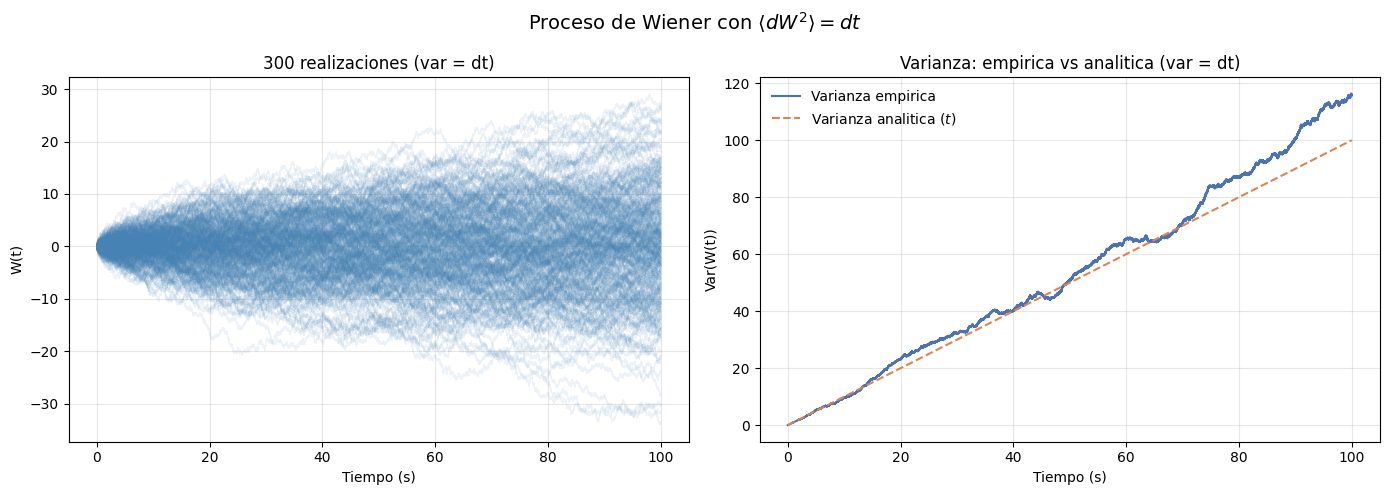

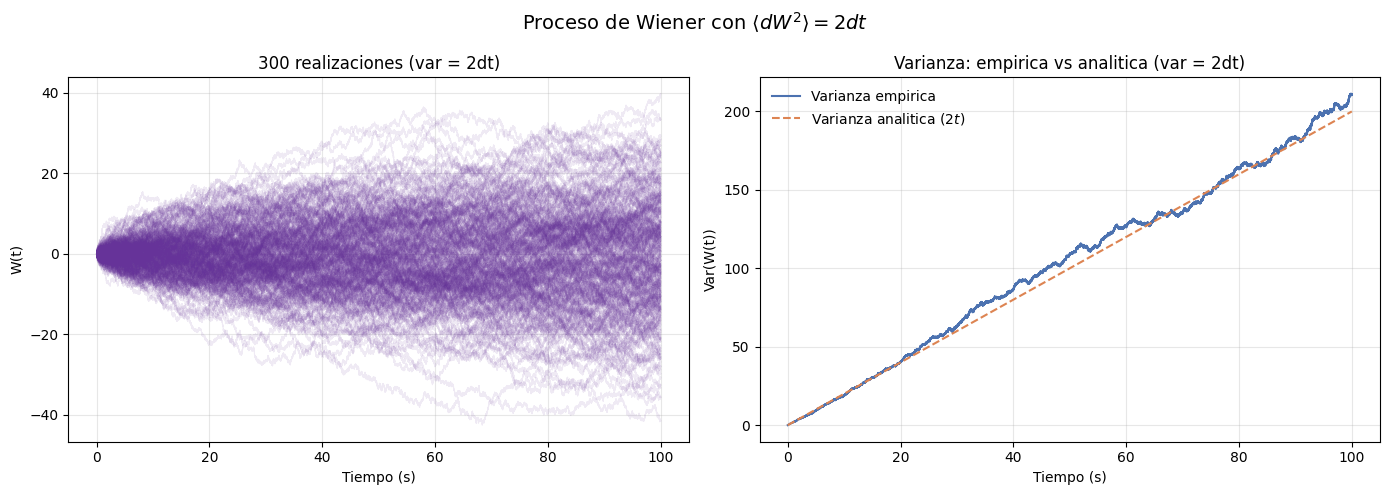

In [20]:
## ----- Comparacion Varianza Empirica vs Analitica: dt vs 2dt -----

dt_fijo = 0.001
t_sim_fijo = 100
num_sims_fijo = 300

# --- Figura 1: Varianza de dt ---
t1, process1, _ = simulacion_wiener(dt_fijo, dw=np.sqrt(dt_fijo), t_sim=t_sim_fijo, num_sims=num_sims_fijo)
var_emp1 = process1.var(axis=0)
var_analitica1 = t1  # Var(W(t)) = t cuando <dW^2> = dt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for i in range(num_sims_fijo):
    axes[0].plot(t1, process1[i], color='steelblue', alpha=0.1, linewidth=0.8)
axes[0].set_xlabel('Tiempo (s)')
axes[0].set_ylabel('W(t)')
axes[0].set_title('300 realizaciones (var = dt)')
axes[0].grid(True, alpha=0.3)

axes[1].plot(t1, var_emp1, color='#4C72B0', linewidth=1.5, label='Varianza empirica')
axes[1].plot(t1, var_analitica1, color='#DD8452', linewidth=1.5, linestyle='--', label='Varianza analitica ($t$)')
axes[1].set_xlabel('Tiempo (s)')
axes[1].set_ylabel('Var(W(t))')
axes[1].set_title('Varianza: empirica vs analitica (var = dt)')
axes[1].legend(loc='upper left', frameon=False)
axes[1].grid(True, alpha=0.3)

fig.suptitle(r'Proceso de Wiener con $\langle dW^2 \rangle = dt$', fontsize=14)
plt.tight_layout()
plt.show()

# --- Figura 2: Varianza de 2dt ---
t2, process2, _ = simulacion_wiener(dt_fijo, dw=np.sqrt(2 * dt_fijo), t_sim=t_sim_fijo, num_sims=num_sims_fijo)
var_emp2 = process2.var(axis=0)
var_analitica2 = 2 * t2  # Var(W(t)) = 2t cuando <dW^2> = 2dt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for i in range(num_sims_fijo):
    axes[0].plot(t2, process2[i], color='rebeccapurple', alpha=0.1, linewidth=0.8)
axes[0].set_xlabel('Tiempo (s)')
axes[0].set_ylabel('W(t)')
axes[0].set_title('300 realizaciones (var = 2dt)')
axes[0].grid(True, alpha=0.3)

axes[1].plot(t2, var_emp2, color='#4C72B0', linewidth=1.5, label='Varianza empirica')
axes[1].plot(t2, var_analitica2, color='#DD8452', linewidth=1.5, linestyle='--', label='Varianza analitica ($2t$)')
axes[1].set_xlabel('Tiempo (s)')
axes[1].set_ylabel('Var(W(t))')
axes[1].set_title('Varianza: empirica vs analitica (var = 2dt)')
axes[1].legend(loc='upper left', frameon=False)
axes[1].grid(True, alpha=0.3)

fig.suptitle(r'Proceso de Wiener con $\langle dW^2 \rangle = 2dt$', fontsize=14)
plt.tight_layout()
plt.show()


## Parte 4 

### Proceso de Ornstein-Uhlenbeck

El proceso de Ornstein-Uhlenbeck se utiliza para describir la velocidad de una partícula Browniana en un medio, o para describir la posición de una partícula sobreamortiguada en una trampa. Está dado por la siguiente expresión:

$$
dx = -kx\,dt + g\,dW
$$

1. Demuestra que la distribución $P(x,t)$ tiene un estado estacionario, y encuentra la media y la varianza de esta distribución.

2. Realiza una simulación numérica en la que compruebes que se obtiene este estado final.

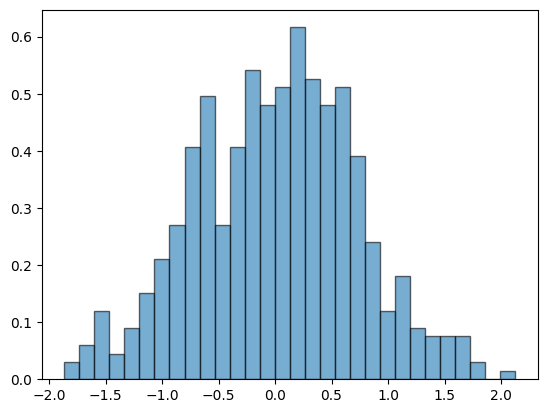

In [ ]:
import numpy as np
import matplotlib.pyplot as plt



# Condiciones iniciales
x0, k, g = 1, 1, 1
t_sim = 100
dt = 0.001
N = int(t_sim/dt)
num_sims = 100



def ornstein_uhlbenbeck(x0=1, k=1, g=1, dt=0.001, t_sim=100, num_sims=500):
    N = int(t_sim/dt)
    x = np.zeros((num_sims, N +1))
    t = np.linspace(0, t_sim, N+1)
    x[:,0] = x0
    dW = np.random.randn(num_sims, N) * np.sqrt(dt)
    for i in range(N):
        x[:, i+1] = x[:,i] - k*x[:,i]*dt + g*dW[:, i]
    return x, t    

x, t = ornstein_uhlbenbeck()

# plt.figure(figsize=(10,5))
# plt.plot(t, x[0], color='steelblue', linewidth=1)
# plt.xlabel("dx")

plt.hist(x[:, -1], bins=30, density=True, alpha=0.6, label="simulado", edgecolor="black")
plt.show() 